In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
possible_filenames = ["heart.csv"]
dataset_path = next((name for name in possible_filenames if os.path.exists(name)), None)

if dataset_path is None:
    raise FileNotFoundError(
        "Could not find heart.csv. "
        "Please put the CSV file in the same folder as this notebook."
    )

df = pd.read_csv(dataset_path)

print(f"Loaded file: {dataset_path}")
print(f"Dataset has {df.shape[0]} rows and {df.shape[1]} columns.")
df.head()

Loaded file: heart.csv
Dataset has 1025 rows and 14 columns.


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [5]:
# Show the column names
print("Column names:")
print(df.columns.tolist())

# Show each column's data type and non-missing count
print("\nDataset information:")
df.info()

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [6]:
# Summary statistics for numerical columns
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [7]:
# Count missing values in each column
missing_values = df.isnull().sum().sort_values(ascending=False)
print(missing_values)

print("\nTotal missing values:", int(df.isnull().sum().sum()))

# Count exact duplicate rows; inspect this before deciding whether to remove any.
print("Exact duplicate rows:", int(df.duplicated().sum()))

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Total missing values: 0
Exact duplicate rows: 723


In [8]:
if "target" not in df.columns:
    raise ValueError("The dataset must contain a 'target' column.")

X = df.drop(columns=["target"])
y = df["target"]

print("Number of input features:", X.shape[1])
print("Feature names:", X.columns.tolist())
print("Target name:", y.name)
print("\nTarget counts:")
print(y.value_counts().sort_index())

Number of input features: 13
Feature names: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Target name: target

Target counts:
target
0    499
1    526
Name: count, dtype: int64


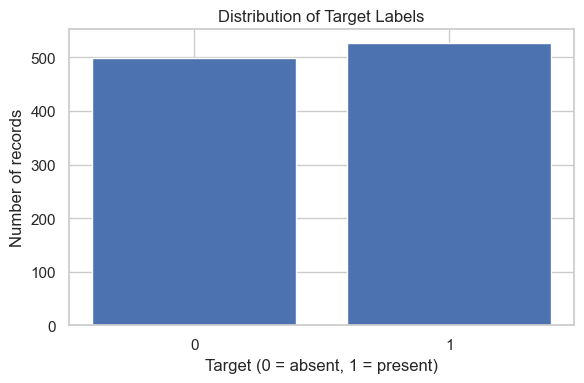

In [9]:
# Chart 1: Number of records in each target class
plt.figure(figsize=(6, 4))
target_counts = df["target"].value_counts().sort_index()
plt.bar(target_counts.index.astype(str), target_counts.values)
plt.title("Distribution of Target Labels")
plt.xlabel("Target (0 = absent, 1 = present)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

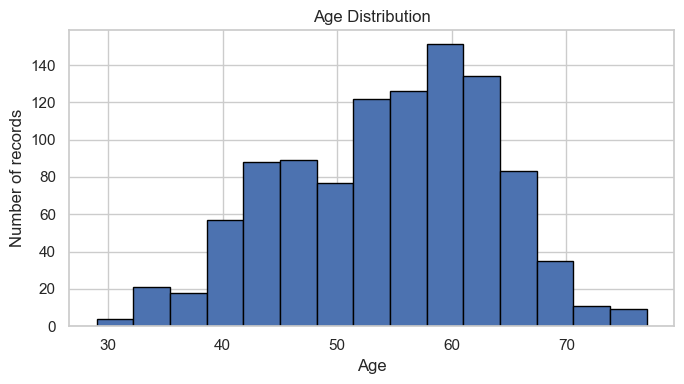

In [10]:
# Chart 2: Distribution of patient ages
plt.figure(figsize=(7, 4))
plt.hist(df["age"], bins=15, edgecolor="black")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

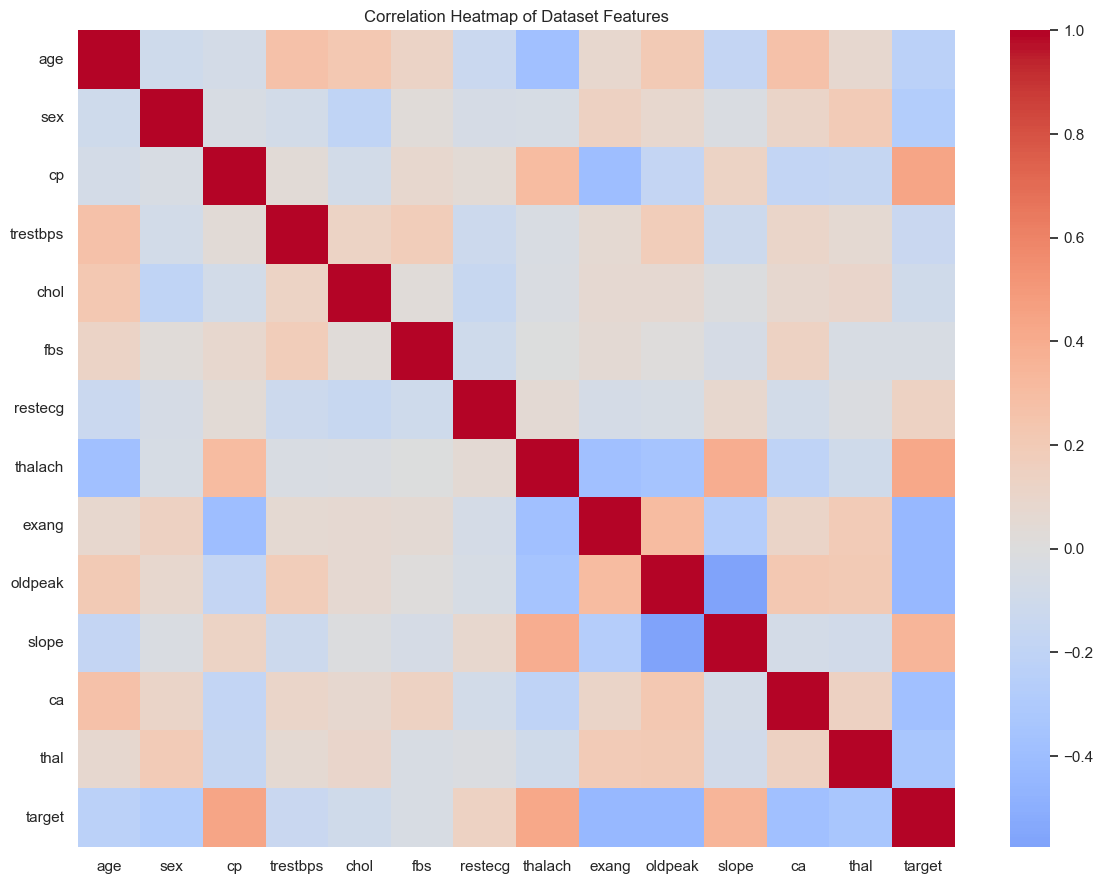

In [11]:
# Chart 3: Correlation heatmap for the numerical columns
plt.figure(figsize=(12, 9))
correlation_matrix = df.corr(numeric_only=True)
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap of Dataset Features")
plt.tight_layout()
plt.show()

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(3))
print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Training features: (820, 13)
Testing features: (205, 13)

Training target proportions:
target
0    0.487
1    0.513
Name: proportion, dtype: float64

Testing target proportions:
target
0    0.488
1    0.512
Name: proportion, dtype: float64


In [13]:
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

# Train the pipeline using only the training data
model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


In [14]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Accuracy:  {accuracy:.3f} ({accuracy * 100:.1f}%)")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")

print("\nDetailed classification report:")
print(classification_report(y_test, y_pred, zero_division=0))

# ROC AUC is available when the test data contains both classes.
if y_test.nunique() == 2:
    auc = roc_auc_score(y_test, y_probability)
    print(f"ROC AUC:   {auc:.3f}")
else:
    auc = np.nan
    print("ROC AUC was not calculated because the test data contains only one class.")

Accuracy:  0.810 (81.0%)
Precision: 0.762
Recall:    0.914
F1-score:  0.831

Detailed classification report:
              precision    recall  f1-score   support

           0       0.89      0.70      0.78       100
           1       0.76      0.91      0.83       105

    accuracy                           0.81       205
   macro avg       0.82      0.81      0.81       205
weighted avg       0.82      0.81      0.81       205

ROC AUC:   0.930


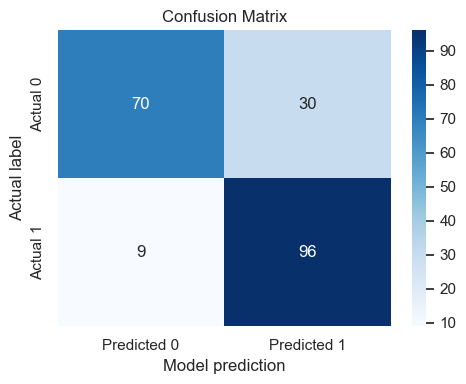

In [15]:
# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.title("Confusion Matrix")
plt.xlabel("Model prediction")
plt.ylabel("Actual label")
plt.tight_layout()
plt.show()

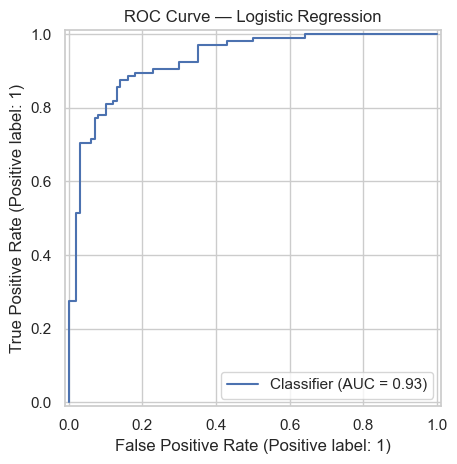

In [16]:
# Plot the ROC curve to see how well the model separates the two classes.
if y_test.nunique() == 2:
    RocCurveDisplay.from_predictions(y_test, y_probability)
    plt.title("ROC Curve — Logistic Regression")
    plt.tight_layout()
    plt.show()
else:
    print("ROC curve is unavailable because the test data contains only one class.")

In [17]:
classifier = model.named_steps["classifier"]

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": classifier.coef_[0]
})
coefficients["Absolute coefficient"] = coefficients["Coefficient"].abs()
coefficients = coefficients.sort_values("Absolute coefficient", ascending=False)

coefficients

,Feature,Coefficient,Absolute coefficient
2,cp,0.867769,0.867769
1,sex,-0.781747,0.781747
11,ca,-0.745506,0.745506
9,oldpeak,-0.614295,0.614295
8,exang,-0.517055,0.517055
12,thal,-0.499174,0.499174
7,thalach,0.411778,0.411778
10,slope,0.365533,0.365533
3,trestbps,-0.362392,0.362392
4,chol,-0.275126,0.275126


In [18]:
print("CONCLUSION")
print("----------")
print(
    f"The Logistic Regression model was trained on {len(X_train)} records "
    f"and evaluated on {len(X_test)} test records."
)
print(f"Test accuracy was {accuracy:.3f} ({accuracy * 100:.1f}%).")
print(f"Precision was {precision:.3f}, recall was {recall:.3f}, and F1-score was {f1:.3f}.")
if not np.isnan(auc):
    print(f"ROC AUC was {auc:.3f}.")
print(
    "This exercise demonstrated data exploration, preprocessing, classification, "
    "and model evaluation with Pandas and Scikit-learn."
)
print(
    "This model is for coursework only. Its results do not establish a diagnosis "
    "and should not be used as a substitute for professional medical evaluation."
)

CONCLUSION
----------
The Logistic Regression model was trained on 820 records and evaluated on 205 test records.
Test accuracy was 0.810 (81.0%).
Precision was 0.762, recall was 0.914, and F1-score was 0.831.
ROC AUC was 0.930.
This exercise demonstrated data exploration, preprocessing, classification, and model evaluation with Pandas and Scikit-learn.
This model is for coursework only. Its results do not establish a diagnosis and should not be used as a substitute for professional medical evaluation.
